# 03 · Mineração de padrões

A EDA mostrou crescimento estrutural **e** uma queda recente. Aqui aplicamos técnicas de mineração de dados
para separar sinal de ruído e responder com rigor estatístico:

| # | Técnica | Pergunta |
|---|---|---|
| 1 | **STL robusta** (decomposição sazonal-tendência via LOESS) | Qual é a tendência subjacente, sem sazonalidade e ruído? |
| 2 | **PELT** (detecção de pontos de mudança) | Em quais regimes de crescimento o setor já esteve? |
| 3 | **Análise de drawdowns** (event study) | A queda atual é inédita? Quanto tempo as anteriores levaram para se recuperar? |
| 4 | **Correlação cruzada + causalidade de Granger** | Vagas antecedem o emprego? O que os sinais atuais indicam? |
| 5 | **K-Means + PCA em trajetórias** | O ciclo de tech é único ou faz parte de um padrão mais amplo? |
| 6 | **Mann-Kendall + Theil-Sen** | A tendência europeia é estatisticamente significativa? |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from techdemand import analysis as an, config, data_sources as ds, features as ft, style

warnings.filterwarnings("ignore", category=FutureWarning)
style.apply()
%matplotlib inline

panel = ds.fetch_fred_panel()
tech = ft.tech_employment(panel)
TECH = style.color_for("Núcleo tech")

## 1. Decomposição STL: tendência vs. ruído

Aplicamos STL robusta ao **log** do emprego. A componente de tendência, diferenciada em 12 meses,
dá a **taxa de crescimento estrutural anualizada** — a métrica usada no resto da análise.

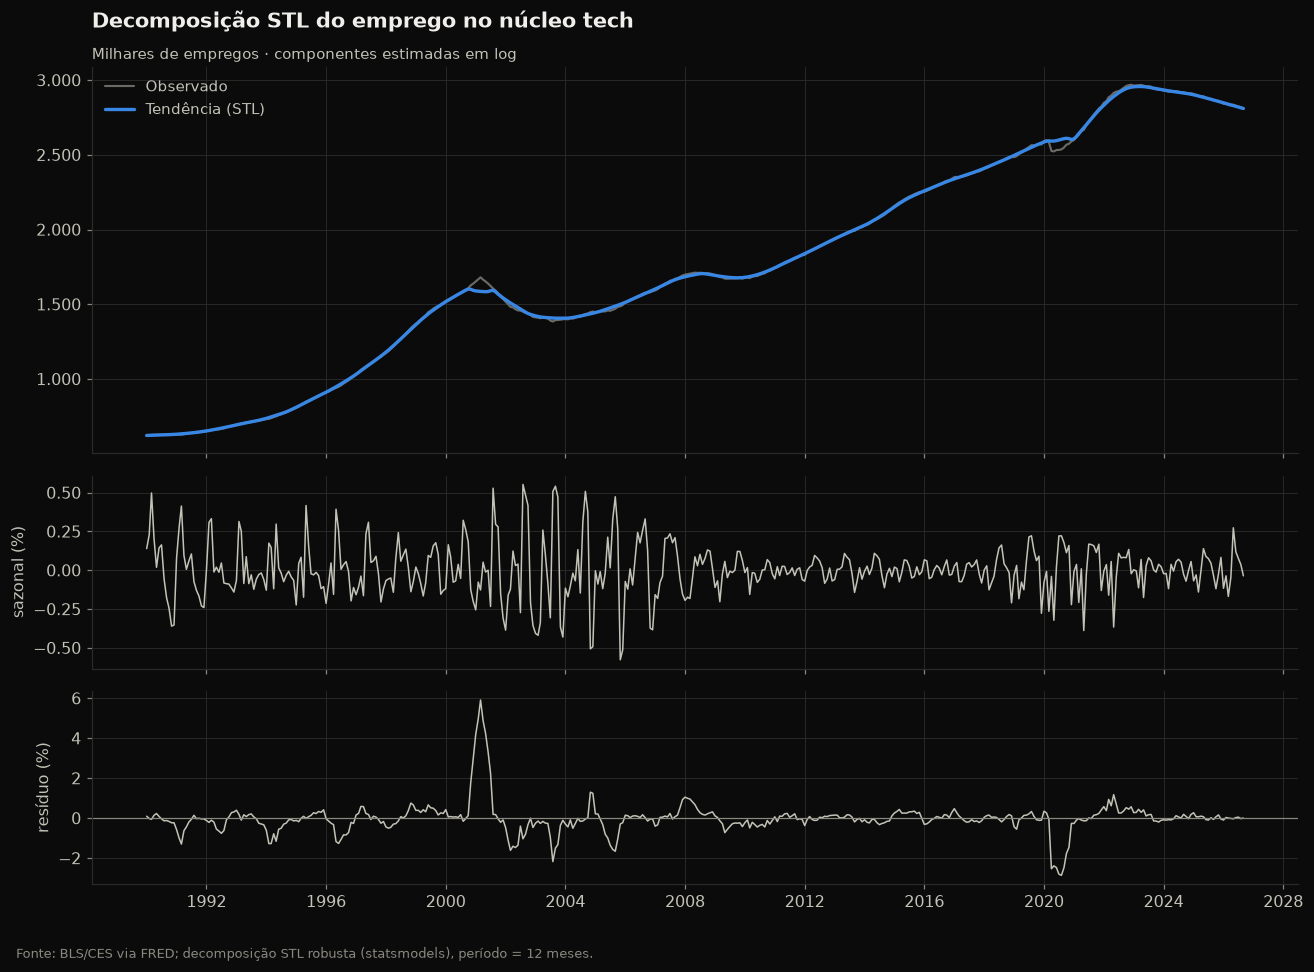

Amplitude sazonal: ±0.58% · desvio do resíduo: 0.79%
→ Os dados já têm ajuste sazonal; a variação é quase toda tendência + ciclo.


In [2]:
stl = an.stl_log(tech)
fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
axes[0].plot(stl.index, np.exp(stl["observed"]), color=style.NEUTRAL, lw=1.4, label="Observado")
axes[0].plot(stl.index, np.exp(stl["trend"]), color=TECH, lw=2.2, label="Tendência (STL)")
axes[0].legend(loc="upper left")
style.thousands_axis(axes[0])
axes[0].set_title("Decomposição STL do emprego no núcleo tech")
style.subtitle(axes[0], "Milhares de empregos · componentes estimadas em log")
axes[1].plot(stl.index, stl["seasonal"] * 100, color=style.TEXT_SECONDARY, lw=1)
axes[1].set_ylabel("sazonal (%)")
axes[2].plot(stl.index, stl["resid"] * 100, color=style.TEXT_SECONDARY, lw=1)
axes[2].axhline(0, color=style.TEXT_MUTED, lw=0.8)
axes[2].set_ylabel("resíduo (%)")
style.source(fig, "BLS/CES via FRED; decomposição STL robusta (statsmodels), período = 12 meses.")
fig.tight_layout()
style.save(fig, "03_01_stl")
plt.show()

forca_tendencia = 1 - stl["resid"].var() / (stl["observed"] - stl["seasonal"]).diff().var()
print(f"Amplitude sazonal: ±{stl['seasonal'].abs().max() * 100:.2f}% · desvio do resíduo: {stl['resid'].std() * 100:.2f}%")
print("→ Os dados já têm ajuste sazonal; a variação é quase toda tendência + ciclo.")

## 2. Regimes de crescimento (PELT)

O algoritmo **PELT** (*Pruned Exact Linear Time*) encontra o número ótimo de quebras na média da taxa
de crescimento da tendência, penalizando quebras em excesso. Cada regime é um período com dinâmica própria.

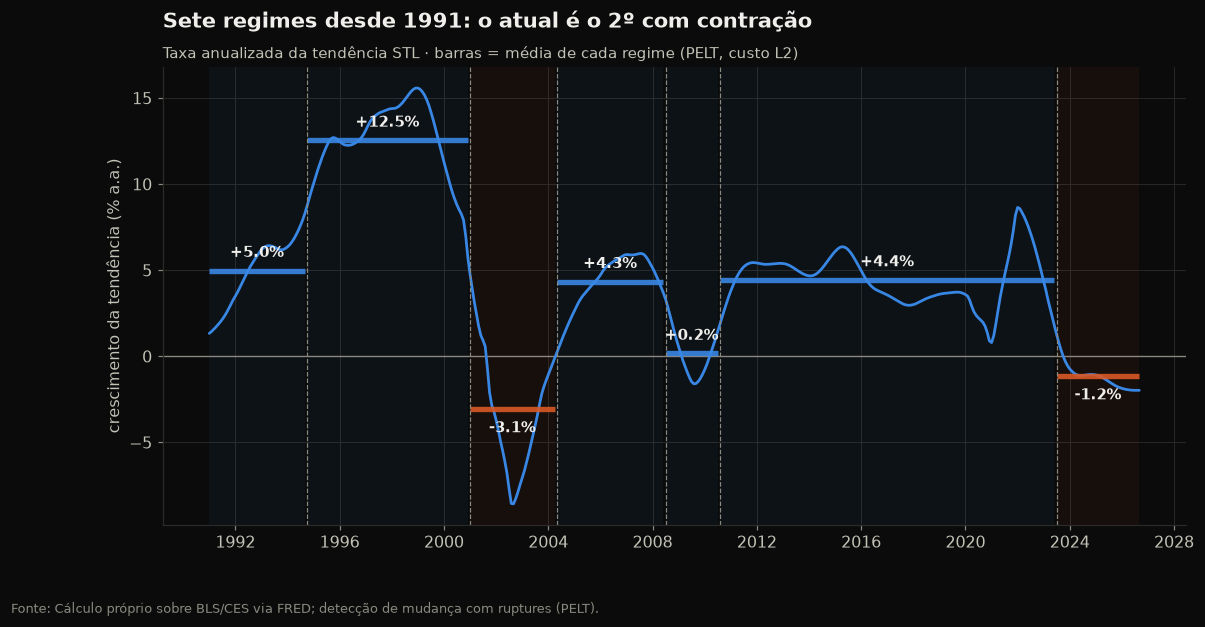

,início,fim,meses,média,desvio
0,1991-01,1994-09,45,4.98,2.00
1,1994-10,2000-12,75,12.54,2.26
2,2001-01,2004-04,40,-3.08,3.67
3,2004-05,2008-06,50,4.33,1.62
4,2008-07,2010-07,25,0.16,1.45
5,2010-08,2023-06,155,4.43,1.54
6,2023-07,2026-09,39,-1.17,0.76


In [3]:
growth = stl["trend_growth"].dropna()
breaks = an.change_points(growth, penalty=5)
reg = an.regimes(growth, breaks)

fig, ax = plt.subplots(figsize=(12, 5.4))
ax.axhline(0, color=style.TEXT_MUTED, lw=0.9)
ax.plot(growth.index, growth, color=TECH, lw=1.8)
for _, r in reg.iterrows():
    cor = style.DIVERGING[2] if r["média"] > 0 else style.DIVERGING[0]
    ax.hlines(r["média"], r["início"], r["fim"], color=cor, lw=3.5, alpha=0.9)
    ax.axvspan(r["início"], r["fim"], color=cor, alpha=0.06, lw=0)
    ax.annotate(f"{r['média']:+.1f}%", (r["início"] + (r["fim"] - r["início"]) / 2, r["média"]),
                xytext=(0, 9 if r["média"] > 0 else -15), textcoords="offset points",
                ha="center", fontsize=9.5, color=style.TEXT_PRIMARY, fontweight="bold")
for b in breaks:
    ax.axvline(b, color=style.TEXT_MUTED, lw=0.8, ls="--")
ax.set_ylabel("crescimento da tendência (% a.a.)")
ax.set_title("Sete regimes desde 1991: o atual é o 2º com contração")
style.subtitle(ax, "Taxa anualizada da tendência STL · barras = média de cada regime (PELT, custo L2)")
style.source(fig, "Cálculo próprio sobre BLS/CES via FRED; detecção de mudança com ruptures (PELT).")
style.save(fig, "03_02_regimes")
plt.show()

reg_fmt = reg.assign(início=reg["início"].dt.strftime("%Y-%m"), fim=reg["fim"].dt.strftime("%Y-%m"))
reg_fmt.round(2)

## 3. A queda atual é inédita? (*event study* de drawdowns)

Cada episódio é alinhado no seu pico (mês 0 = 100). Assim comparamos profundidade, duração
e velocidade de recuperação de todos os ciclos de queda desde 1990.

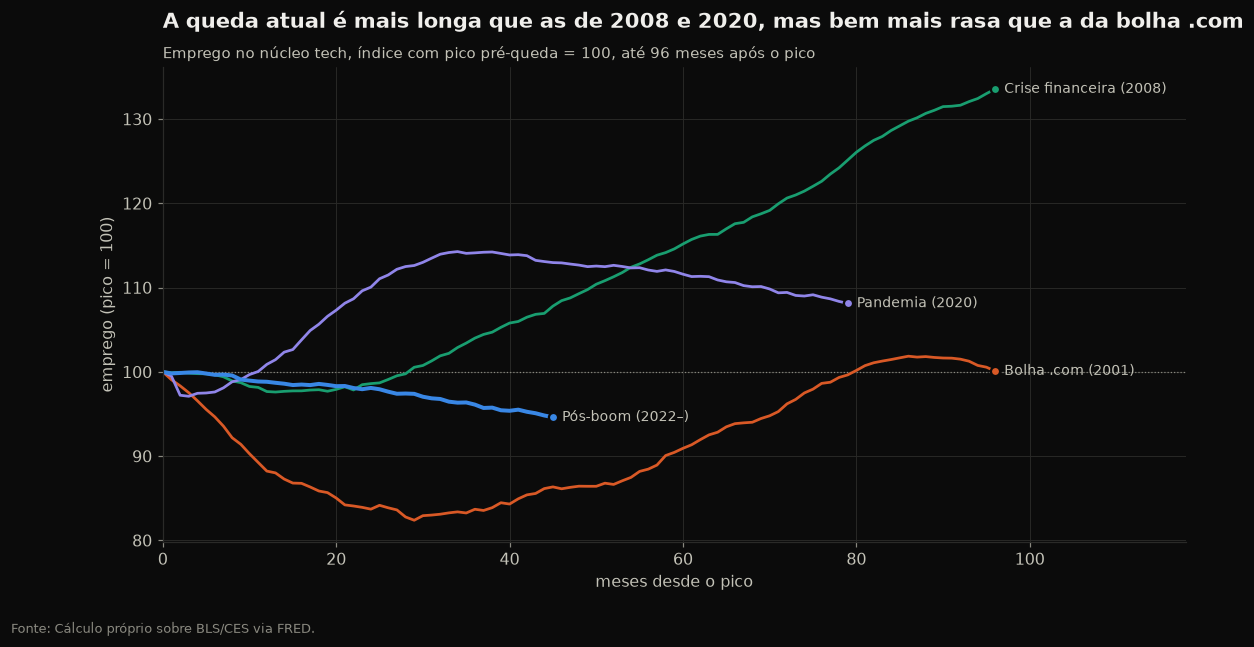

,episódio,pico,vale,queda (%),meses até o vale,meses até recuperar,crescimento 5 anos após recuperar (%)
0,Bolha .com (2001),2001-03,2003-08,-17.6,29,80,14.3
1,Crise financeira (2008),2008-05,2009-06,-2.4,13,29,30.3
2,Pandemia (2020),2020-02,2020-05,-2.9,3,11,9.3
3,Pós-boom (2022–),2022-12,2026-09,-5.4,45,em curso,—


In [4]:
dds = an.drawdowns(tech, min_depth_pct=2)
nomes_ep = {2001: "Bolha .com (2001)", 2008: "Crise financeira (2008)", 2020: "Pandemia (2020)", 2022: "Pós-boom (2022–)"}
cores_ep = dict(zip(nomes_ep.values(), [style.PALETTE[1], style.PALETTE[2], style.PALETTE[6], style.PALETTE[0]]))

fig, ax = plt.subplots(figsize=(12, 5.6))
ax.axhline(100, color=style.TEXT_MUTED, lw=0.8, ls=":")
for dd in dds:
    nome = nomes_ep[dd.peak.year]
    seg = tech.loc[dd.peak: dd.peak + pd.DateOffset(months=96)]
    meses = np.arange(len(seg))
    ax.plot(meses, seg / seg.iloc[0] * 100, color=cores_ep[nome], lw=2.6 if "2022" in nome else 1.8)
    style.label_line_end(ax, meses[-1], (seg / seg.iloc[0] * 100).iloc[-1], nome, cores_ep[nome])
ax.set_xlabel("meses desde o pico")
ax.set_ylabel("emprego (pico = 100)")
ax.set_xlim(0, 118)
ax.set_title("A queda atual é mais longa que as de 2008 e 2020, mas bem mais rasa que a da bolha .com")
style.subtitle(ax, "Emprego no núcleo tech, índice com pico pré-queda = 100, até 96 meses após o pico")
style.source(fig, "Cálculo próprio sobre BLS/CES via FRED.")
style.save(fig, "03_03_drawdowns")
plt.show()

pd.DataFrame([{
    "episódio": nomes_ep[d.peak.year], "pico": d.peak.strftime("%Y-%m"), "vale": d.trough.strftime("%Y-%m"),
    "queda (%)": round(d.depth_pct, 1), "meses até o vale": d.months_to_trough,
    "meses até recuperar": d.months_to_recover if d.months_to_recover is not None else "em curso",
    "crescimento 5 anos após recuperar (%)": round((tech.loc[:d.recovery + pd.DateOffset(years=5)].iloc[-1]
                                                 / tech.loc[d.recovery] - 1) * 100, 1) if d.recovery is not None else "—",
} for d in dds])

## 4. Indicadores antecedentes: vagas preveem emprego?

Se as vagas **antecedem** o emprego, os sinais de hoje dizem algo sobre os próximos meses.
Testamos isso de duas formas:

- **Correlação cruzada** entre a variação anual das vagas do setor de Informação (JOLTS) e do emprego tech, por defasagem.
- **Causalidade de Granger** (variações mensais em log, 2002–2019, período sem a distorção da pandemia), nos dois sentidos.

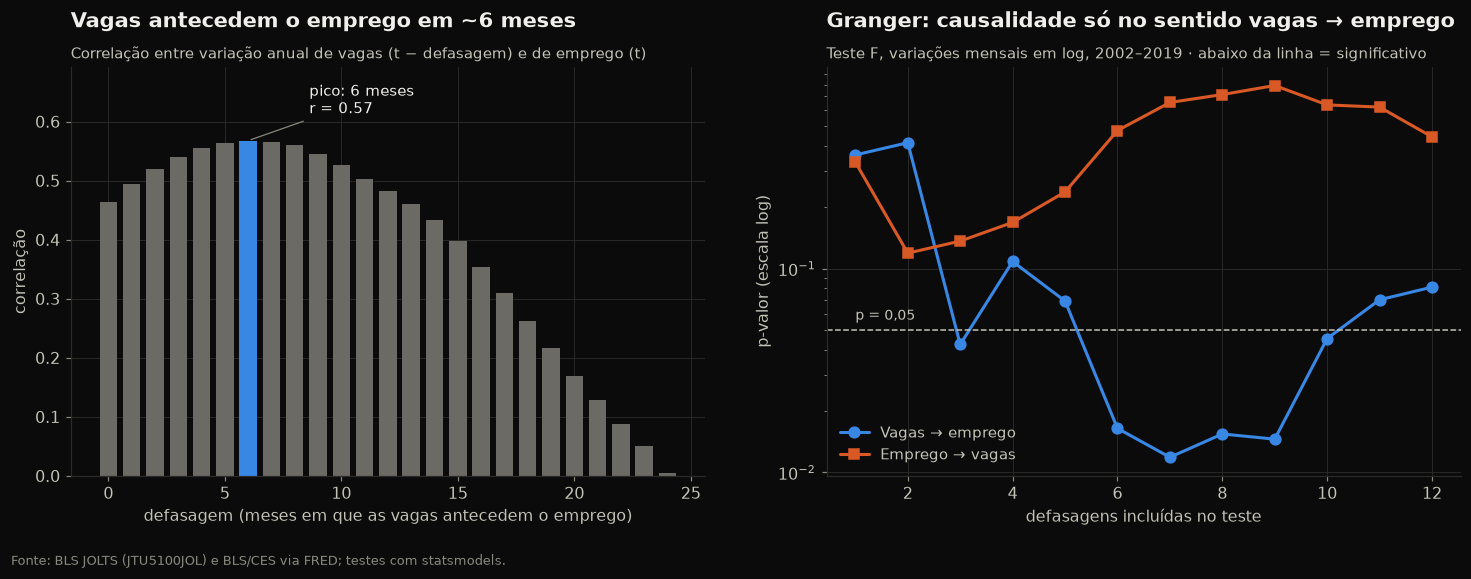

Defasagens significativas (p < 0,05) vagas → emprego: [3, 6, 7, 8, 9, 10]
Defasagens significativas (p < 0,05) emprego → vagas: []


In [5]:
vagas_yoy = ft.yoy(panel["JTU5100JOL"].rolling(3).mean())
emp_yoy = ft.yoy(tech)
ccf = an.lead_lag_corr(vagas_yoy, emp_yoy, max_lag=24)

d_emp = np.log(tech).diff() * 100
d_vag = np.log(panel["JTU5100JOL"].rolling(3).mean()).diff() * 100
periodo = slice("2002", "2019")
g_fwd = an.granger_pvalues(d_vag.loc[periodo], d_emp.loc[periodo], 12)
g_rev = an.granger_pvalues(d_emp.loc[periodo], d_vag.loc[periodo], 12)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.bar(ccf.index, ccf.values, color=[TECH if l == ccf.idxmax() else style.NEUTRAL for l in ccf.index],
        width=0.75)
ax1.annotate(f"pico: {ccf.idxmax()} meses\nr = {ccf.max():.2f}", (ccf.idxmax(), ccf.max()),
             xytext=(40, 18), textcoords="offset points", color=style.TEXT_PRIMARY, fontsize=9.5,
             arrowprops=dict(arrowstyle="-", color=style.TEXT_MUTED, lw=0.8))
ax1.set_ylim(0, ccf.max() * 1.22)
ax1.set_xlabel("defasagem (meses em que as vagas antecedem o emprego)")
ax1.set_ylabel("correlação")
ax1.set_title("Vagas antecedem o emprego em ~6 meses")
style.subtitle(ax1, "Correlação entre variação anual de vagas (t − defasagem) e de emprego (t)")

ax2.plot(g_fwd.index, g_fwd, "o-", color=TECH, ms=7, label="Vagas → emprego")
ax2.plot(g_rev.index, g_rev, "s-", color=style.PALETTE[1], ms=7, label="Emprego → vagas")
ax2.axhline(0.05, color=style.TEXT_SECONDARY, lw=1, ls="--")
ax2.text(1, 0.054, "p = 0,05", va="bottom", fontsize=9, color=style.TEXT_SECONDARY)
ax2.set_yscale("log")
ax2.set_xlabel("defasagens incluídas no teste")
ax2.set_ylabel("p-valor (escala log)")
ax2.legend(loc="lower left")
ax2.set_title("Granger: causalidade só no sentido vagas → emprego")
style.subtitle(ax2, "Teste F, variações mensais em log, 2002–2019 · abaixo da linha = significativo")
style.source(fig, "BLS JOLTS (JTU5100JOL) e BLS/CES via FRED; testes com statsmodels.")
fig.tight_layout()
style.save(fig, "03_04_indicadores_antecedentes")
plt.show()

print("Defasagens significativas (p < 0,05) vagas → emprego:", list(g_fwd[g_fwd < 0.05].index))
print("Defasagens significativas (p < 0,05) emprego → vagas:", list(g_rev[g_rev < 0.05].index))

### O que os indicadores antecedentes mostram hoje

In [6]:
soft = panel["IHLIDXUSTPSOFTDEVE"].dropna()
jolts = panel["JTU5100JOL"].dropna()
sinais = pd.DataFrame({
    "último": [soft.iloc[-1], jolts.rolling(12).mean().iloc[-1]],
    "variação 6 meses (%)": [(soft.iloc[-1] / soft.iloc[-7] - 1) * 100,
                             (jolts.rolling(12).mean().iloc[-1] / jolts.rolling(12).mean().iloc[-7] - 1) * 100],
    "variação 12 meses (%)": [(soft.iloc[-1] / soft.iloc[-13] - 1) * 100,
                              (jolts.rolling(12).mean().iloc[-1] / jolts.rolling(12).mean().iloc[-13] - 1) * 100],
}, index=["Indeed: vagas de software (índice)", "JOLTS: vagas setor de Informação (mil, média 12m)"])
sinais.round(1)

,último,variação 6 meses (%),variação 12 meses (%)
Indeed: vagas de software (índice),78.3,7.5,20.6
"JOLTS: vagas setor de Informação (mil, média 12m)",93.8,-19.6,-26.5


> **Leitura honesta:** os dois sinais divergem. Os anúncios de **software** no Indeed — a medida mais específica
> de demanda tech — sobem há mais de um ano. Já as vagas do **setor de Informação** como um todo (que inclui mídia,
> editoras e telecom) seguem caindo. Como as vagas antecedem o emprego em ~6 meses, a expectativa de curto prazo é
> de **estabilização** do emprego tech, não de retomada forte imediata.

## 5. Clusterização de trajetórias: o ciclo é exclusivo de tech?

Cada uma das 47 áreas do Indeed (EUA) vira um vetor com sua trajetória mensal (log do índice) desde 2020.
O **K-Means** agrupa áreas com ciclos parecidos; o *k* é escolhido pelo **coeficiente de silhueta**, e a
**PCA** projeta os vetores em 2D para visualização.

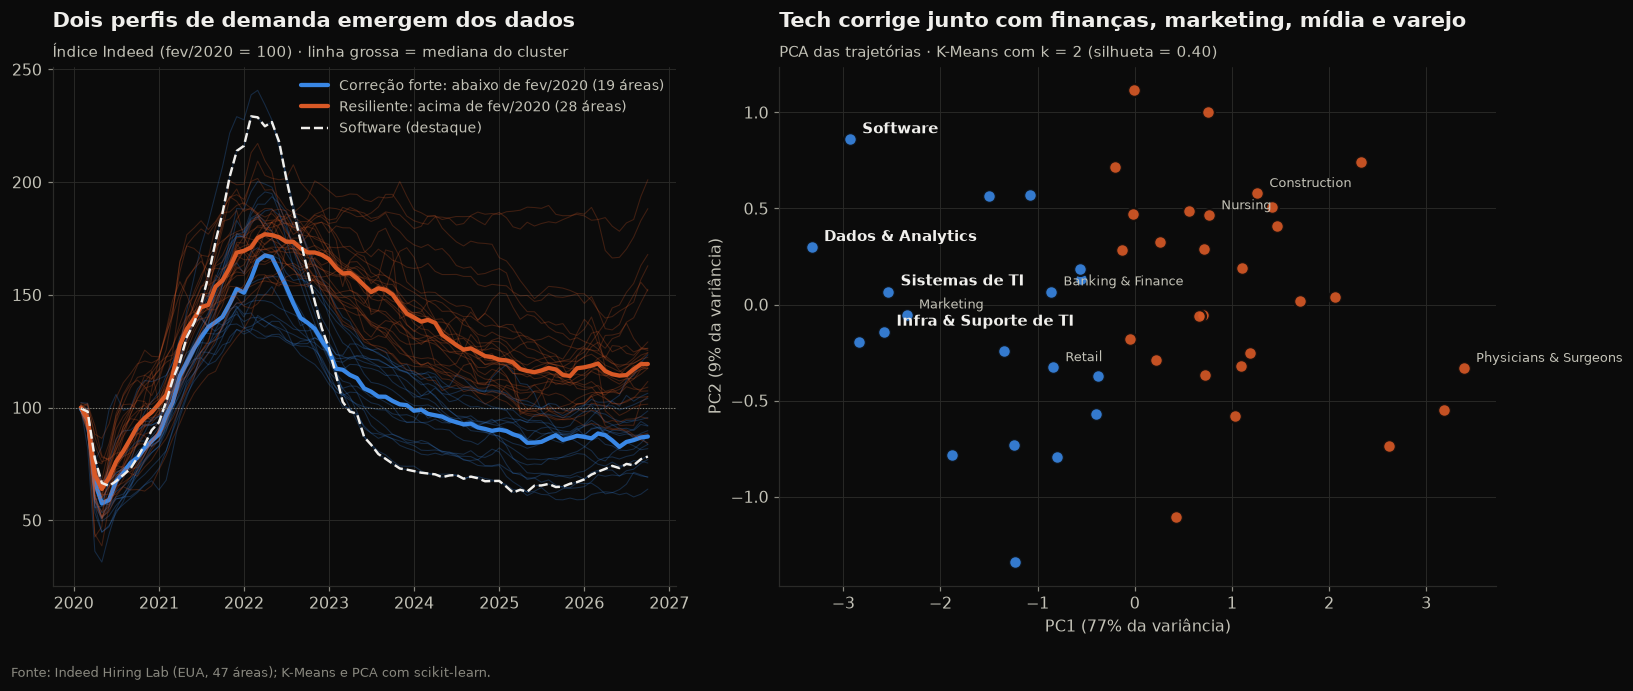

Correção forte: abaixo de fev/2020: Architecture, Arts & Entertainment, Banking & Finance, Customer Service, Data & Analytics, Driving, Food Preparation & Service, Hospitality & Tourism, Human Resources, IT Infrastructure, Operations & Support, IT Systems & Solutions, Industrial Engineering, Management, Marketing, Media & Communications, Retail, Sales, Scientific Research & Development, Software Development

Resiliente: acima de fev/2020: Accounting, Administrative Assistance, Aviation, Childcare, Civil Engineering, Cleaning & Sanitation, Community & Social Service, Construction, Dental, Education & Instruction, Electrical Engineering, Installation & Maintenance, Insurance, Legal, Loading & Stocking, Logistic Support, Mechanical Engineering, Medical Information, Medical Technician, Nursing, Personal Care & Home Health, Pharmacy, Physicians & Surgeons, Production & Manufacturing, Project Management, Security & Public Safety, Social Science, Therapy



In [7]:
ind_us = ds.fetch_indeed_sectors("US")
ind_us = ind_us[ind_us["variable"] == "total postings"]
wide = ind_us.pivot_table(index="date", columns="sector", values="index").resample("MS").mean()
cl = an.cluster_trajectories(wide)
labels, coords = cl["labels"], cl["coords"]
tech_cluster = labels[config.TECH_SECTORS].mode()[0]
nome_cl = {tech_cluster: "Correção forte: abaixo de fev/2020", 1 - tech_cluster: "Resiliente: acima de fev/2020"}
cor_cl = {tech_cluster: style.PALETTE[0], 1 - tech_cluster: style.PALETTE[1]}
nomes_tech = {"Software Development": "Software", "Data & Analytics": "Dados & Analytics",
              "IT Infrastructure, Operations & Support": "Infra & Suporte de TI", "IT Systems & Solutions": "Sistemas de TI"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.15]})
for c in sorted(labels.unique()):
    membros = labels[labels == c].index
    traj = wide[membros]
    for m in membros:
        ax1.plot(traj.index, traj[m], color=cor_cl[c], lw=0.7, alpha=0.25)
    ax1.plot(traj.index, traj.median(axis=1), color=cor_cl[c], lw=2.8, label=f"{nome_cl[c]} ({len(membros)} áreas)")
ax1.plot(wide.index, wide["Software Development"], color=style.TEXT_PRIMARY, lw=1.6, ls="--", label="Software (destaque)")
ax1.axhline(100, color=style.TEXT_MUTED, lw=0.7, ls=":")
ax1.legend(loc="upper right", fontsize=9)
ax1.set_title("Dois perfis de demanda emergem dos dados")
style.subtitle(ax1, "Índice Indeed (fev/2020 = 100) · linha grossa = mediana do cluster")

for c in sorted(labels.unique()):
    pts = coords[labels == c]
    ax2.scatter(pts["pc1"], pts["pc2"], s=70, color=cor_cl[c], edgecolor=style.SURFACE, lw=1.5, alpha=0.9)
for sec, nome in nomes_tech.items():
    x, y = coords.loc[sec]
    ax2.annotate(nome, (x, y), xytext=(8, 4), textcoords="offset points", fontsize=9.5,
                 color=style.TEXT_PRIMARY, fontweight="bold")
for sec in ["Nursing", "Banking & Finance", "Marketing", "Construction", "Retail", "Physicians & Surgeons"]:
    x, y = coords.loc[sec]
    ax2.annotate(sec, (x, y), xytext=(8, 4), textcoords="offset points", fontsize=8.5, color=style.TEXT_SECONDARY)
ax2.set_xlabel(f"PC1 ({cl['explained'][0] * 100:.0f}% da variância)")
ax2.set_ylabel(f"PC2 ({cl['explained'][1] * 100:.0f}% da variância)")
ax2.set_title("Tech corrige junto com finanças, marketing, mídia e varejo")
style.subtitle(ax2, f"PCA das trajetórias · K-Means com k = {cl['k']} (silhueta = {cl['silhouette'].max():.2f})")
style.source(fig, "Indeed Hiring Lab (EUA, 47 áreas); K-Means e PCA com scikit-learn.")
fig.tight_layout()
style.save(fig, "03_05_clusters")
plt.show()

for c in sorted(labels.unique()):
    print(f"{nome_cl[c]}: {', '.join(sorted(labels[labels == c].index))}\n")

> A queda de vagas tech **não é um fenômeno isolado**: o K-Means coloca as 4 áreas tech no mesmo grupo de
> finanças, marketing, RH, mídia, varejo e hotelaria — áreas cuja demanda corrigiu para **abaixo** do nível
> pré-pandemia, sensíveis a juros e ao ciclo de consumo/investimento. O grupo resiliente, ainda acima de fev/2020,
> é dominado por saúde, educação, engenharias e construção. Isso é evidência de um componente **macroeconômico/cíclico** forte na queda recente.
> A clusterização, sozinha, não descarta efeitos estruturais (ex.: IA); por isso olhamos também emprego e projeções.

## 6. Europa: a tendência é estatisticamente significativa?

Para cada país aplicamos o teste não-paramétrico de **Mann-Kendall** (existe tendência monotônica?) e o
estimador robusto de **Theil-Sen** (de quantos pontos percentuais por ano?), com intervalo de confiança de 95%.
A janela começa em 2012 para evitar a quebra de série de 2011 (ISCO-08). Ambos os métodos são baseados em postos
e medianas, portanto pouco sensíveis a quebras menores (ex.: nova metodologia da pesquisa de força de trabalho em 2021).

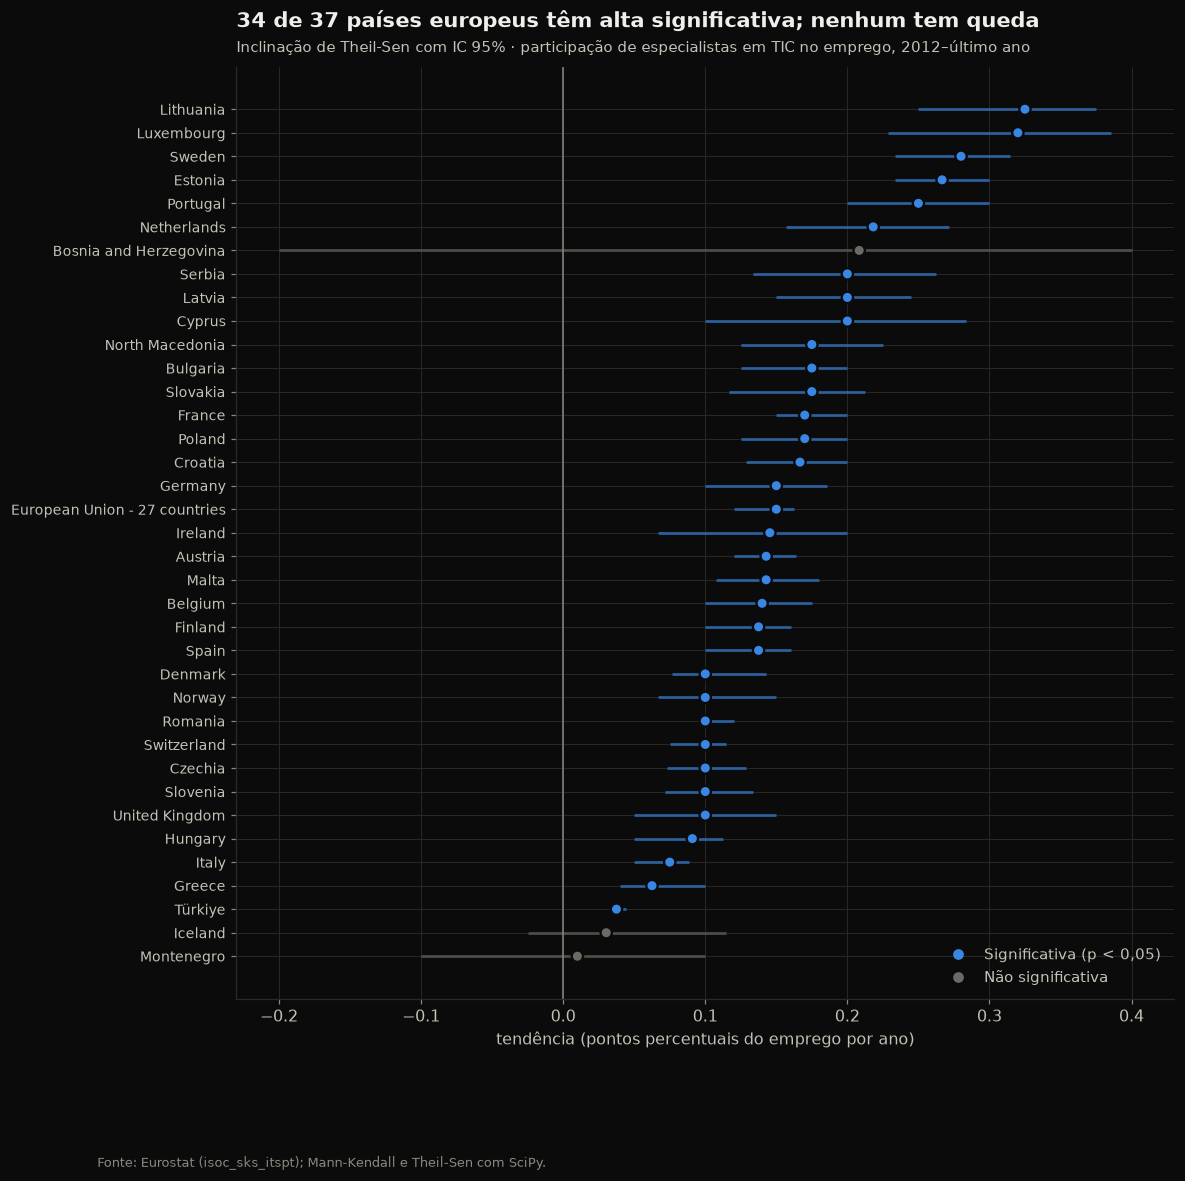

Tendência significativa de alta: 34 · de queda: 0
Mediana da inclinação: +0.145 p.p./ano


In [8]:
eu = ds.fetch_eurostat_ict()
pc = eu[(eu.unit == "PC_EMP") & (eu.time >= 2012)]
mk = pc.groupby("geo_name").apply(lambda d: pd.Series(an.mann_kendall(d.set_index("time")["value"])))
mk.index = mk.index.str.replace(r" \(.*\)", "", regex=True)
mk = mk.sort_values("slope")
sig = mk["p_value"] < 0.05

fig, ax = plt.subplots(figsize=(11, 11))
y = np.arange(len(mk))
cores = [style.PALETTE[0] if s else style.NEUTRAL for s in sig]
ax.hlines(y, mk["slope_lo"], mk["slope_hi"], color=cores, lw=2, alpha=0.6)
ax.scatter(mk["slope"], y, color=cores, s=55, edgecolor=style.SURFACE, lw=1.5, zorder=3)
ax.axvline(0, color=style.TEXT_MUTED, lw=1)
ax.set_yticks(y, mk.index, fontsize=9)
ax.set_xlabel("tendência (pontos percentuais do emprego por ano)")
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=style.PALETTE[0]),
                   plt.Line2D([], [], marker="o", ls="", color=style.NEUTRAL)],
          labels=["Significativa (p < 0,05)", "Não significativa"], loc="lower right")
ax.set_title(f"{sig.sum()} de {len(mk)} países europeus têm alta significativa; nenhum tem queda")
style.subtitle(ax, "Inclinação de Theil-Sen com IC 95% · participação de especialistas em TIC no emprego, 2012–último ano")
style.source(fig, "Eurostat (isoc_sks_itspt); Mann-Kendall e Theil-Sen com SciPy.")
style.save(fig, "03_06_europa_tendencias")
plt.show()

print(f"Tendência significativa de alta: {(sig & (mk.slope > 0)).sum()} · de queda: {(sig & (mk.slope < 0)).sum()}")
print(f"Mediana da inclinação: +{mk['slope'].median():.3f} p.p./ano")

## Síntese da mineração de padrões

1. **A tendência estrutural é de alta**, interrompida por regimes de contração curtos. Em 35 anos houve
   apenas 2 regimes negativos (bolha .com e o atual), e o regime atual é bem mais brando (≈ −1% a.a. vs ≈ −3%).
2. **Após a maior queda da história (bolha .com, −17,6%)** o setor recuperou o pico e seguiu crescendo:
   quedas foram, até hoje, **pausas** em uma trajetória ascendente.
3. **Vagas antecedem emprego** (Granger significativo vagas → emprego, não o inverso). A retomada dos anúncios de
   software desde 2025 sugere estabilização à frente; o sinal mais amplo do setor de Informação ainda é fraco.
4. **O ciclo atual tem forte componente macro**: tech oscila junto com finanças, marketing, mídia e varejo
   (clusterização), e não sozinho.
5. **Na Europa a alta é generalizada e estatisticamente robusta.**

Esses padrões alimentam os modelos de previsão do notebook 04.